# Плей-офф НХЛ 2025/2026: анализ событий матчей

Используются библиотеки `numpy`, `pandas`, `matplotlib` и `seaborn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rink import plot_rink

# Выводим дробные числа с тремя знаками после запятой, как в примерах из условия
pd.set_option('display.precision', 3)

## Пункт 1. Чтение данных

**Условие.** Прочитайте данные из файла `NHL-playoffs-2026.xlsx` в набор данных `pandas`.

**Решение.** Данные хранятся в таблице Excel, поэтому читаем их функцией `pd.read_excel()`. Единственная тонкость связана с первым столбцом файла: в нем записаны просто номера строк, а не данные о событиях. Если ничего не указать, pandas прочитает его как обычный столбец, и таблица получится из 39 столбцов вместо 38. Поэтому мы делаем этот столбец индексом таблицы (`index_col=0`).

Правильность загрузки проверяем сравнением с примером из условия: размер таблицы `events.shape` должен быть (29710, 38), а первые десять строк выбранных столбцов должны совпадать с таблицей из примера. Оба условия выполняются.

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)
events.shape

(29710, 38)

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


**Выводы и комментарии.**

Данные загружены полностью и без искажений: 29710 событий и 38 полей, ровно как в примере. Каждая строка описывает одно событие матча (вбрасывание, бросок, силовой прием, удаление и так далее), и для каждого события известны время, тип, команда и игроки, совершившие действие, координаты на площадке и составы обеих команд на льду. Именно из этих событий дальше собираются все показатели по играм, командам и игрокам.

## Пункт 2. Сводная таблица по играм

**Условие.** Соберите краткую сводную информацию по каждой игре в отдельный набор данных `pandas`. В таблице должны быть дата, названия команд, сколько голов они забили и сколько овертаймов понадобилось, если таковые были.

**Решение.** Исходная таблица состоит из событий, а нужна таблица, где одна строка соответствует одной игре. Поэтому события группируются по номеру игры `Game ID`, и для каждой группы вычисляются нужные характеристики.

Дата и названия команд во всех событиях одного матча одинаковые, так что их можно взять из любого события, мы берем первое (`first()`). Итоговый счет в таблице отдельно не записан, зато в каждом событии есть счет на момент этого события (`Cumulated Away Score` и `Cumulated Home Score`). Счет по ходу матча может только расти, поэтому итоговый счет равен максимальному значению этих полей в матче.

Число овертаймов определяется по номеру последнего периода. В основное время играется три периода, поэтому если последний период третий, матч закончился в основное время (`Final`), если четвертый, понадобился один овертайм (`Final/OT`), если пятый, два овертайма (`Final/2OT`). В плей-офф овертаймы играются до первой заброшенной шайбы и без буллитов, поэтому каждый матч заканчивается победой одной из команд, а число овертаймов не ограничено. Функция `outcome` записана так, что правильно обработает любое их число.

В конце, чтобы опереться на эти данные в выводах, мы считаем, сколько матчей закончилось каждым исходом, сколько серий было в каждом раунде и кто выиграл каждую серию. Номер игры устроен так, что последняя цифра это номер матча в серии, предпоследняя номер серии, а цифра перед ней номер раунда. Поэтому номер серии получается целочисленным делением номера игры на 10, а номер раунда это последняя цифра номера серии. Победителя матча определяем сравнением голов хозяев и гостей, а число побед каждой команды в каждой серии считаем группировкой по серии и победителю.

In [4]:
g = events.groupby('Game ID')
games = pd.DataFrame({'Date': g['Date'].first(),
                      'Away Team': g['Away Team'].first(),
                      'Home Team': g['Home Team'].first(),
                      'Away Score': g['Cumulated Away Score'].max(),
                      'Home Score': g['Cumulated Home Score'].max(),
                      'Periods': g['Period'].max()})

def outcome(periods):
    if periods == 3:
        return 'Final'
    elif periods == 4:
        return 'Final/OT'
    else:
        return 'Final/%dOT' % (periods - 3)

games['Outcome'] = games['Periods'].map(outcome)
games = games.drop(['Periods'], axis=1)
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

In [5]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [6]:
len(games)

82

In [7]:
games['Outcome'].value_counts()

Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

In [8]:
# Номер серии и номер раунда, закодированные в номере игры
seriesId = games.index // 10
print('Всего серий:', len(set(seriesId)))
pd.Series(sorted(set(seriesId))).map(lambda s: s // 10 % 10).value_counts().sort_index()

Всего серий: 15


1    8
2    4
3    2
4    1
Name: count, dtype: int64

In [9]:
# Победитель каждого матча и счет каждой серии
winner = np.where(games['Home Score'] > games['Away Score'], games['Home Team'], games['Away Team'])
seriesResults = pd.DataFrame({'Series': seriesId, 'Winner': winner}).groupby(['Series', 'Winner']).size()
seriesResults

Series     Winner              
202503011  Boston Bruins           2
           Buffalo Sabres          4
202503012  Montréal Canadiens      4
           Tampa Bay Lightning     3
202503013  Carolina Hurricanes     4
202503014  Philadelphia Flyers     4
           Pittsburgh Penguins     2
202503015  Colorado Avalanche      4
202503016  Dallas Stars            2
           Minnesota Wild          4
202503017  Utah Mammoth            2
           Vegas Golden Knights    4
202503018  Anaheim Ducks           4
           Edmonton Oilers         2
202503021  Buffalo Sabres          3
           Montréal Canadiens      4
202503022  Carolina Hurricanes     4
202503023  Colorado Avalanche      4
           Minnesota Wild          1
202503024  Anaheim Ducks           2
           Vegas Golden Knights    4
202503031  Carolina Hurricanes     4
           Montréal Canadiens      1
202503032  Vegas Golden Knights    4
202503041  Carolina Hurricanes     4
           Vegas Golden Knights    2
dtype:

**Выводы и комментарии.**

1. В данных 82 матча плей-офф. Номер игры устроен так, что в нем закодированы раунд, серия и номер матча в серии, и по нему видно 15 серий: 8 в первом раунде, 4 во втором, 2 в финалах конференций и финал.

2. 60 матчей закончились в основное время, 18 потребовали одного овертайма и 4 двух овертаймов. Получается, что больше четверти матчей (22 из 82) не определили победителя за 60 минут. Это типично для плей-офф, где соперники близки по силе и игра становится более осторожной.

3. Последние пять строк таблицы совпадают с примером из условия, значит, итоговый счет и число овертаймов определены правильно.

## Пункт 3. Функция gameInfo

**Условие.** Так как в последующих заданиях часто будет необходимо вывести информацию о какой-нибудь игре, напишите функцию `gameInfo(gameId)`, которая бы возвращала ее, скажем, как в примере: `Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)`.

**Решение.** Функция берет готовую строку из таблицы `games` по номеру игры, поэтому ничего не пересчитывает заново. Формат определяется по примеру из условия: в примере Buffalo Sabres стоит первым и забил 4 гола, а Boston Bruins вторым и забил 3, при этом Buffalo играл дома. Значит, сначала пишется команда хозяев, затем команда гостей, и счет записывается в том же порядке: голы хозяев, затем голы гостей. После счета идут исход матча из пункта 2 и дата.

Функция возвращает строку, а не печатает ее. Это важно, потому что дальше ее результат используется внутри других вычислений: из таких строк собираются списки игр в пунктах 6 и 21, таблица в пункте 7 и заголовок графика в пункте 15.

In [10]:
def gameInfo(gameId):
    row = games.loc[gameId]
    return '%s - %s (%s - %s, %s, %s)' % (row['Home Team'], row['Away Team'],
                                          row['Home Score'], row['Away Score'],
                                          row['Outcome'], row['Date'])

gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [11]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

**Выводы и комментарии.**

Функция проверена на первой и последней игре плей-офф, и оба результата совпадают с примерами из условия. Первая игра, Buffalo Sabres - Boston Bruins 4:3, открывала первый раунд 19 апреля, а последняя, Vegas Golden Knights - Carolina Hurricanes 0:3, была шестым матчем финала 14 июня. В этом матче Carolina Hurricanes выиграла серию со счетом 4-2 и стала чемпионом.

## Пункт 4. Число голов в игре

**Условие.** Сосчитайте, сколько всего было забито шайб в каждой игре (поля `Away Score` и `Home Score` в таблице игр) и выведите описательные статистики для этого показателя.

**Решение.** Общее число голов в матче равно сумме голов хозяев и гостей, поэтому просто складываем столбцы `Away Score` и `Home Score` и сохраняем результат в таблицу игр как новый столбец `Total Score`, он понадобится в пунктах 5 и 6. Описательные статистики получаем методом `describe()`: число наблюдений, среднее, стандартное отклонение, минимум, максимум и квартили. Результат совпадает с примером из условия.

In [12]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

**Выводы и комментарии.**

1. В среднем в матче забивали 5.93 гола, а медиана равна 6, то есть в половине матчей было 6 голов или больше. Среднее и медиана почти совпадают, поэтому типичный матч плей-офф заканчивается примерно с 6 голами на двоих.

2. Первый и третий квартили равны 5 и 7. Это значит, что в половине всех матчей забили от 5 до 7 шайб, то есть основная масса матчей сосредоточена в узком диапазоне.

3. Стандартное отклонение 2.26 показывает, что разброс все же заметный: обычным можно считать матч с 4-8 голами.

4. Минимум равен 1, а максимум 15. Максимум отстоит от среднего на (15 - 5.93) / 2.26, то есть примерно на 4 стандартных отклонения. Это явный выброс, один необычно результативный матч, о котором подробнее в пунктах 5 и 6.

## Пункт 5. Гистограмма числа голов

**Условие.** Изобразите гистограмму показателя, сосчитанного в предыдущем пункте. Для гистограммы дискретной величины можно использовать функцию `seaborn.countplot()`. Не забывайте про подписи на осях. Прокомментируйте полученный результат.

**Решение.** Число голов в матче принимает только целые значения, поэтому обычная гистограмма с интервалами здесь не нужна: достаточно для каждого значения нарисовать столбик высотой, равной числу матчей. Это и делает `countplot`.

Важная деталь касается значений, которых нет в данных. Матчей с 12, 13 и 14 голами не было, и по умолчанию `countplot` просто не показал бы эти значения на оси, а столбик для 15 голов встал бы сразу за столбиком для 11. Тогда выброс выглядел бы как обычное соседнее значение. Поэтому мы явно задаем все значения от 1 до 15 (параметр `order`), и пустые места на оси показывают, насколько матч с 15 голами оторван от остальных. Чтобы комментарий опирался на точные числа, а не на оценку на глаз, рядом выводим таблицу частот.

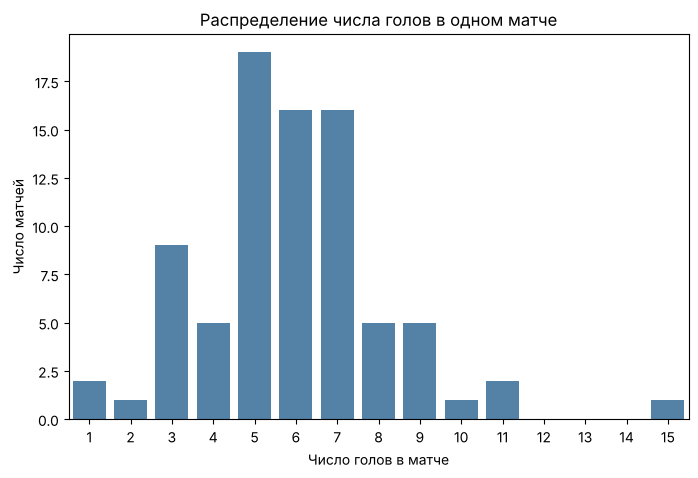

In [13]:
plt.figure(figsize=(8, 5))
sns.countplot(x=games['Total Score'], order=range(1, 16), color='steelblue')
plt.xlabel('Число голов в матче')
plt.ylabel('Число матчей')
plt.title('Распределение числа голов в одном матче')
plt.show()

In [14]:
games['Total Score'].value_counts().sort_index()

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64

**Выводы и комментарии.**

1. Распределение имеет один явный пик: чаще всего в матче забивали 5 голов (19 матчей из 82). Чуть реже встречаются 6 и 7 голов, по 16 матчей. Вместе на значения от 5 до 7 приходится 51 матч, то есть 62% всех игр.

2. Слева от пика картина неровная: матчей с 3 голами 9, а с 4 голами только 5, хотя по общей форме распределения можно было бы ожидать обратного. Скорее всего, это случайность, ведь 82 матча это небольшая выборка, и в отдельных значениях разница в несколько матчей вполне возможна.

3. Распределение несимметрично, у него длинный правый хвост. Очень мало голов забивают редко: матчей с 1-2 голами всего 3. Зато много голов встречается чаще: 14 матчей с 8 голами и больше, в том числе матчи с 10 и 11 голами.

4. Матч с 15 голами (Colorado Avalanche - Minnesota Wild, 9:6) стоит отдельно: между ним и следующим значением, 11 голами, три пустых места. Это выброс, необычный матч, а не часть основного распределения.

5. Правый хвост объясняется самой природой величины. Снизу число голов ограничено нулем, а сверху ничем, поэтому отклонения вверх могут быть большими, а вниз нет. Кроме того, в концовках матчей проигрывающая команда часто снимает вратаря, и в пустые ворота забивают дополнительные голы, что тоже сдвигает распределение вправо.

## Пункт 6. Самые нерезультативные и самые результативные игры

**Условие.** Выведите список самых нерезультативных и самых результативных игр.

**Решение.** Самые нерезультативные игры это игры с минимальным общим числом голов, самые результативные с максимальным. Таких игр может быть несколько, поэтому функции вроде `idxmin()` и `idxmax()` здесь не подходят: они вернули бы только первую найденную игру. Вместо этого находим само минимальное (максимальное) значение и отбираем все игры, у которых число голов ему равно. Для каждой найденной игры выводим описание через `gameInfo`.

In [15]:
minScore = games['Total Score'].min()
[gameInfo(gameId) for gameId in games[games['Total Score'] == minScore].index]

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [16]:
maxScore = games['Total Score'].max()
[gameInfo(gameId) for gameId in games[games['Total Score'] == maxScore].index]

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

**Выводы и комментарии.**

1. Самыми нерезультативными оказались две игры со счетом 1:0: Montreal Canadiens - Tampa Bay Lightning и Philadelphia Flyers - Pittsburgh Penguins. Обе закончились в овертайме, то есть за 60 минут основного времени в них не было забито ни одной шайбы. Это игры, где решающую роль сыграли вратари: Andrei Vasilevskiy (Tampa Bay) и Dan Vladar (Philadelphia) провели их без пропущенных голов (это видно и в пункте 21).

2. Самая результативная игра одна: Colorado Avalanche - Minnesota Wild, 9:6, во втором раунде. Это тот самый выброс из пунктов 4 и 5. Интересно, что Minnesota забила 6 голов и все равно проиграла, а Colorado в итоге выиграла эту серию 4-1.

## Пункт 7. Число игроков в игре

**Условие.** Для каждой игры сосчитайте, сколько игроков обеих команд в ней участвовало (поля `Away Team's Player on the Ice #1` - `#6` и `Home Team's Player on the Ice #1` - `#6`, вратарей тоже считаем). Выведите список игр с наибольшим числом участвовавших игроков.

**Решение.** Задача сводится к подсчету разных людей, которые хотя бы раз были на льду в данном матче. Для этого по каждой игре собираем все фамилии из 14 столбцов: шести столбцов игроков на льду и столбца вратаря у каждой из двух команд. Фамилии складываем во множество, которое само убирает повторы. Это важно сразу по двум причинам: один и тот же игрок появляется в сотнях событий матча, а вратарь записан одновременно и в столбце вратаря, и среди шести игроков на льду, но посчитан он должен быть один раз.

Отдельно нужно разобраться с пустыми значениями. Если команда играет в меньшинстве, на льду у нее не шесть человек, а пять, и один из столбцов в строке остается пустым (NaN). Пустое значение не является игроком, поэтому перед подсчетом мы его выбрасываем (`dropna()`). Если этого не сделать, NaN попадет во множество как отдельный элемент и увеличит результат на единицу. Именно так получается число 41 в примере из условия, что мы показываем отдельной ячейкой.

Для выводов дополнительно считаем, в скольких матчах участвовало 38, 39 и 40 человек, и смотрим, какие вратари выходили на лед в матче с наибольшим числом игроков.

In [17]:
cols = []
for team in ['Away', 'Home']:
    for i in range(1, 7):
        cols.append("%s Team's Player on the Ice #%d" % (team, i))
    cols.append("%s Team's Goalie" % team)

def countPlayers(df):
    names = set()
    for col in cols:
        names = names | set(df[col].dropna())
    return len(names)

playerCount = events.groupby('Game ID')[cols].apply(countPlayers)
playerCount.describe()

count    82.000
mean     38.122
std       0.365
min      38.000
25%      38.000
50%      38.000
75%      38.000
max      40.000
dtype: float64

In [18]:
top = playerCount[playerCount == playerCount.max()]
pd.DataFrame({'Game Info': [gameInfo(gameId) for gameId in top.index],
              'Player Count': top.values}, index=top.index)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


In [19]:
names = set()
game216 = events[events['Game ID'] == 2025030216]
for col in cols:
    names = names | set(game216[col])
print(len(names))
print([name for name in names if not isinstance(name, str)])

41
[nan]


In [20]:
playerCount.value_counts()

38    73
39     8
40     1
Name: count, dtype: int64

In [21]:
print('Вратари гостей:', list(game216["Away Team's Goalie"].dropna().unique()))
print('Вратари хозяев:', list(game216["Home Team's Goalie"].dropna().unique()))

Вратари гостей: ['Alex Lyon', 'Ukko-Pekka Luukkonen']
Вратари хозяев: ['Jakub Dobes', 'Jacob Fowler']


**Выводы и комментарии.**

1. В 73 матчах из 82 участвовало ровно 38 человек. Это объясняется правилами: в заявку на матч команда включает 18 полевых игроков и 2 вратарей, но второй вратарь обычно весь матч сидит на скамейке и на лед не выходит. Получается 19 человек на команду и 38 на матч.

2. В 8 матчах участвовало 39 человек. Это матчи, где одна из команд по ходу игры заменила вратаря, и на лед вышел запасной.

3. Больше всего игроков, 40, было в одном матче: Montreal Canadiens - Buffalo Sabres, 3:8. В нем вратарей поменяли обе команды: у Montreal вместо Jakub Dobes вышел Jacob Fowler, а у Buffalo вместо Alex Lyon вышел Ukko-Pekka Luukkonen. Для Montreal, пропустившего 8 голов, замена вратаря вполне ожидаема, но и у победившей команды по ходу матча сменился вратарь, поэтому в этой игре участвовало сразу на 2 человека больше обычного.

4. В примере из условия для этой игры указано 41 игрок. Последняя ячейка показывает, что 41 получается, если не удалять пустые значения: тогда во множество попадает `nan`. Пустые значения здесь означают не потерянного игрока, а отсутствие шестого человека на льду во время удалений, поэтому правильный ответ 40.

## Пункт 8. Расстояние до ворот

**Условие.** Рассмотрите броски в створ ворот и прошедшие мимо ворот. Для каждого броска сосчитайте расстояние до ворот по полям `X Coordinate on the Ice Rink` и `Y Coordinate on the Ice Rink` для событий типа `shot-on-goal`, `goal` (точные броски) и `missed-shot` (неточные броски). Ворота имеют ширину 6 футов, поэтому расстояние считаем до ближайшей точки створа ворот. Координата X ворот равна 89 футов для ворот справа и -89 для ворот слева:

\- d(x, y) = sqrt((x - X)^2 + (y + 3)^2), если y < -3;

\- d(x, y) = |x - X|, если -3 <= y <= 3;

\- d(x, y) = sqrt((x - X)^2 + (y - 3)^2), если y > 3.

Если поле `Home Team's Defending Side` равно `left`, то для бросков хозяев берите расстояние до правых ворот (X = 89), а для бросков гостей до левых (X = -89). Если оно равно `right`, то наоборот. Кто бросает, хозяева или гости, можно понять, сравнив поля `Team Making the Play` и `Home Team`.

**Решение.** Чтобы посчитать расстояние, нужно сначала понять, в какие ворота нанесен бросок. Координаты в данных записаны относительно площадки, а не относительно команды, а команды после каждого периода меняются воротами. Поэтому направление атаки определяется по полю `Home Team's Defending Side`, которое показывает, какие ворота защищают хозяева в данном периоде.

Рассуждение такое. Если хозяева защищают левые ворота, то атакуют правые (X = 89), а гости атакуют левые (X = -89). Если хозяева защищают правые ворота, все наоборот. Отсюда видно, что бросок летит в правые ворота ровно в двух случаях: бросают хозяева, и они защищают левые ворота, или бросают гости, а хозяева защищают правые. В обоих случаях признаки "бросают хозяева" и "хозяева защищают левые ворота" совпадают (оба верны или оба неверны). Поэтому координата ворот равна 89, если эти признаки совпадают, и -89, если нет.

Сами ворота это не точка, а отрезок шириной 6 футов, от y = -3 до y = 3. Расстояние считаем до ближайшей точки этого отрезка. Если бросок сделан прямо напротив ворот (y между -3 и 3), ближайшая точка лежит на линии ворот прямо напротив, и расстояние равно разнице по горизонтали. Если бросок сделан сбоку, ниже или выше ворот, ближайшей точкой будет соответствующая штанга, (X, -3) или (X, 3), и расстояние до нее считается по теореме Пифагора. Все три случая вычисляются сразу для всех строк через `np.where`, без цикла. Для событий, которые не являются бросками, расстояние не имеет смысла, и там записывается NaN.

Для проверки выводим описательные статистики полученных расстояний: минимум, максимум и медиану.

In [22]:
shots = events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])
homeShot = events['Team Making the Play'] == events['Home Team']
homeLeft = events["Home Team's Defending Side"] == 'left'

X = np.where(homeShot == homeLeft, 89, -89)
x = events['X Coordinate on the Ice Rink']
y = events['Y Coordinate on the Ice Rink']

dist = np.where(y < -3, np.sqrt((x - X)**2 + (y + 3)**2),
                np.where(y > 3, np.sqrt((x - X)**2 + (y - 3)**2),
                         np.abs(x - X)))
events['Shot Length'] = np.where(shots, dist, np.nan)

events[shots][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


In [23]:
events['Shot Length'].describe()

count    7266.000
mean       35.409
std        27.471
min         0.000
25%        15.556
50%        31.898
75%        47.877
max       188.215
Name: Shot Length, dtype: float64

**Выводы и комментарии.**

1. Расстояния посчитаны для 7266 бросков (броски в створ, голы и броски мимо), и первые значения совпадают с примером из условия (12.207, 12.000, 29.411 и так далее). Это подтверждает, что ворота для каждого броска определены правильно.

2. Расстояния лежат в пределах от 0 до 188 футов, а медиана около 32 футов (пункт 9). То есть типичный бросок делается примерно с линии кругов вбрасывания. При этом встречаются и броски с расстояния больше длины половины площадки, их происхождение разбирается в пункте 9.

## Пункт 9. Распределение длины точных и неточных бросков

**Условие.** Сравните распределение длины точных и неточных бросков. Для этого постройте гистограммы расстояния до ворот по группам точных и неточных бросков. Функция `seaborn.displot()` как раз годится для этого. Только надо сообразить, как вывести именно распределения, с учетом того, что размеры подвыборок точных и неточных бросков разные. Какой вывод можно сделать из данной гистограммы? Как вы думаете, почему наблюдается такой длинный хвост точных бросков со своей половины площадки?

**Решение.** Главная трудность пункта в том, что группы разного размера: точных бросков 4623, а неточных 2643, почти вдвое меньше. Если нарисовать обычные гистограммы с числом бросков по вертикали, точные броски будут выше почти на всех расстояниях просто потому, что их больше, и сравнить, на каких дистанциях каждый вид бросков встречается чаще, не получится. Поэтому нужно сравнивать не количества, а распределения.

Для этого по вертикали откладывается плотность (`stat='density'`), и плотность считается отдельно для каждой группы (`common_norm=False`). Тогда площадь под каждой гистограммой равна 1, и высота столбика показывает, какая доля бросков данной группы приходится на этот интервал расстояний. Если бы нормировка была общей, обе гистограммы делили бы одну площадь, и большая группа снова выглядела бы выше. Поверх гистограмм рисуется сглаженная кривая плотности (`kde=True`), по которой форму распределения видно лучше.

Гистограмма дает общую картину, но выводы на глаз ненадежны, поэтому мы подкрепляем ее числами. Сначала сравниваем медианы расстояний. Затем делим расстояния на интервалы по 10 футов и в каждом считаем долю точных бросков: так видно, на каких дистанциях бросают точнее. Наконец, отдельно разбираем броски дальше 89 футов, то есть с собственной половины площадки, чтобы проверить объяснения длинного хвоста. Для них проверяем три вещи: из какой зоны сделан бросок, играла ли бросающая команда в меньшинстве и был ли на льду вратарь соперника.

Чтобы понять, насколько необычна доля бросков в меньшинстве среди дальних бросков, ту же долю считаем и для всех бросков.

In [24]:
shotData = events[shots].copy()
shotData['Shot'] = np.where(shotData['Play Type'] == 'missed-shot', 'мимо', 'в створ')
shotData['Shot'].value_counts()

Shot
в створ    4623
мимо       2643
Name: count, dtype: int64

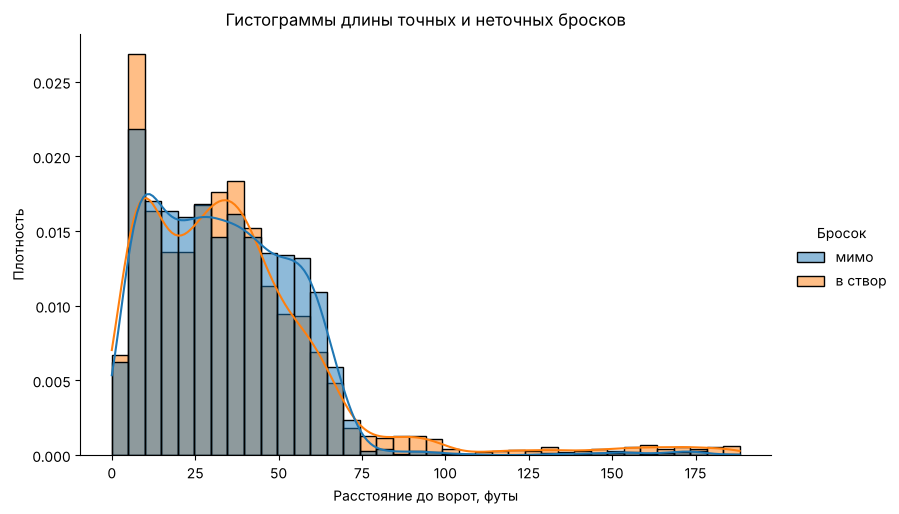

In [25]:
fg = sns.displot(data=shotData, x='Shot Length', hue='Shot', hue_order=['мимо', 'в створ'],
                 stat='density', common_norm=False, kde=True, binwidth=5,
                 height=5, aspect=1.6)
fg.set_axis_labels('Расстояние до ворот, футы', 'Плотность')
fg.legend.set_title('Бросок')
plt.title('Гистограммы длины точных и неточных бросков')
plt.show()

In [26]:
shotData.groupby('Shot')['Shot Length'].median()

Shot
в створ    31.828
мимо       32.249
Name: Shot Length, dtype: float64

In [27]:
shotData['On Goal'] = shotData['Shot'] == 'в створ'
shotData['Distance Group'] = pd.cut(shotData['Shot Length'], [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 200],
                                    include_lowest=True)
shotData.groupby('Distance Group', observed=True)['On Goal'].agg(['mean', 'count'])

,mean,count
Distance Group,,
"(-0.001, 10.0]",0.676,1217
"(10.0, 20.0]",0.608,1079
"(20.0, 30.0]",0.620,1128
"(30.0, 40.0]",0.671,1237
"(40.0, 50.0]",0.624,977
"(50.0, 60.0]",0.542,759
"(60.0, 70.0]",0.552,473
"(70.0, 80.0]",0.703,91
"(80.0, 90.0]",0.892,65


In [28]:
far = shotData[shotData['Shot Length'] > 89].copy()
print('Бросков со своей половины:', len(far))
print(far['Play Type'].value_counts())
print(far['Play Zone'].value_counts())

# Сколько игроков на льду у бросающей команды и у соперника
farHome = far['Team Making the Play'] == far['Home Team']
own = np.where(farHome, far["# of Home Team's Players on the Ice"], far["# of Away Team's Players on the Ice"])
opp = np.where(farHome, far["# of Away Team's Players on the Ice"], far["# of Home Team's Players on the Ice"])
print('Бросающая команда в меньшинстве:', (own < opp).sum())

# Для сравнения: доля бросков в меньшинстве среди всех бросков
allHome = shotData['Team Making the Play'] == shotData['Home Team']
ownAll = np.where(allHome, shotData["# of Home Team's Players on the Ice"], shotData["# of Away Team's Players on the Ice"])
oppAll = np.where(allHome, shotData["# of Away Team's Players on the Ice"], shotData["# of Home Team's Players on the Ice"])
print('Доля бросков в меньшинстве среди дальних: %.2f, среди всех: %.3f'
      % ((own < opp).mean(), (ownAll < oppAll).mean()))

# Вратарь соперника не на льду, то есть бросок по пустым воротам
oppGoalie = np.where(farHome, far["Away Team's Goalie"], far["Home Team's Goalie"])
print('Бросков по пустым воротам:', pd.isna(oppGoalie).sum())

Бросков со своей половины: 251
Play Type
shot-on-goal    202
missed-shot      30
goal             19
Name: count, dtype: int64
Play Zone
Defensive    164
Neutral       87
Name: count, dtype: int64
Бросающая команда в меньшинстве: 65
Доля бросков в меньшинстве среди дальних: 0.26, среди всех: 0.031
Бросков по пустым воротам: 26


**Выводы и комментарии.**

1. В целом распределения точных и неточных бросков похожи. Основная масса бросков обоих видов делается с расстояния от 5 до 70 футов, а медианы почти одинаковые: 31.8 фута у точных и 32.2 у неточных. Значит, расстояние само по себе слабо отличает точный бросок от неточного.

2. Различия видны в деталях. С самого близкого расстояния, до 10 футов, в створ попадает 68% бросков, и пик гистограммы точных бросков в этой зоне выше. Это броски почти в упор, добивания и броски после передачи на пятак, по воротам с такого расстояния промахнуться трудно. С расстояния 50-70 футов точность падает до 54-55%, и на гистограмме неточные броски там идут выше точных. С дальней дистанции бросают в основном защитники от синей линии, шайба летит через скопление игроков, и промахов становится больше.

3. После 80 футов картина резко меняется: почти все такие броски попадают в створ (88-89%). Отсюда на гистограмме длинный хвост точных бросков до 190 футов, тогда как у неточных бросков хвоста почти нет.

4. Почему возникает этот хвост. Бросков дальше 89 футов, то есть со своей половины площадки, 251, и 221 из них попали в створ. Такой бросок почти никогда не бывает настоящей попыткой забить, это в основном выброс шайбы из своей зоны. Это подтверждают данные: 164 таких броска сделаны из собственной зоны защиты, а остальные 87 из средней зоны.

5. 65 дальних бросков сделала команда, игравшая в меньшинстве. Это четверть всех дальних бросков, хотя среди всех бросков доля бросков в меньшинстве всего около 3%. Команда в меньшинстве по правилам может выбрасывать шайбу через всю площадку без проброса, и именно так она снимает давление соперника.

6. Почему такие броски почти всегда записываются как точные. Если выброшенная шайба летит в створ и вратарь ее останавливает, статистика засчитывает бросок в створ. Если же шайба проходит мимо ворот, это обычно фиксируется как проброс или потеря шайбы, а не как бросок мимо. Поэтому в данных есть много дальних точных бросков и почти нет дальних неточных.

7. Еще 26 дальних бросков сделаны по пустым воротам, когда соперник в конце матча снял вратаря ради лишнего полевого игрока. В такой ситуации бросать есть смысл даже из своей зоны, и часть дальних голов забита именно так.

## Пункт 10. Доля точных бросков у каждой команды в каждой игре

**Условие.** Сосчитайте долю точных бросков среди всех незаблокированных бросков у каждой команды в каждой игре. Какой вывод можно сделать из найденной информации?

**Решение.** Незаблокированные броски это броски, которые дошли до ворот или прошли мимо них: броски в створ, голы и броски мимо. Заблокированные броски сюда не входят, потому что их остановил полевой игрок соперника, и по ним нельзя судить, попал бы бросок в створ или нет. Это ровно те броски, которые мы уже отобрали в пункте 9.

Доля точных бросков считается для каждой команды в каждой игре, поэтому броски группируются сразу по двум признакам, игре и команде. Для каждого броска есть признак "попал в створ" (True или False), а среднее такого признака равно доле значений True. Поэтому доля точных бросков это просто среднее этого признака по группе. Вместе с долей выводим общее число незаблокированных бросков и число точных, чтобы было видно, из каких чисел она получена.

Одних описательных статистик мало для содержательного вывода, поэтому мы дополнительно проверяем, связана ли точность с результатом. Для каждой игры сравниваем доли двух команд и смотрим, выиграла ли та, что бросала точнее.

In [29]:
grp = shotData.groupby(['Game ID', 'Team Making the Play'])['On Goal']
numshots = pd.DataFrame({'Unblocked Shots': grp.size(),
                         'Shots on Goal': grp.sum(),
                         'Share of Shots on Goal': grp.mean()})
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [30]:
numshots['Share of Shots on Goal'].describe()

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

In [31]:
accurateWins = 0
for gameId, row in games.iterrows():
    homeShare = numshots.loc[(gameId, row['Home Team']), 'Share of Shots on Goal']
    awayShare = numshots.loc[(gameId, row['Away Team']), 'Share of Shots on Goal']
    homeWon = row['Home Score'] > row['Away Score']
    if (homeShare > awayShare) == homeWon:
        accurateWins += 1
print('Точнее бросавшая команда выиграла %d матчей из %d (%.0f%%)'
      % (accurateWins, len(games), 100 * accurateWins / len(games)))

Точнее бросавшая команда выиграла 37 матчей из 82 (45%)


**Выводы и комментарии.**

1. В среднем в створ попадает около двух третей незаблокированных бросков: и средняя доля, и медиана равны 0.64. Половина всех значений лежит между 0.58 и 0.69, то есть в типичном матче команда попадает в створ 58-69% бросков.

2. Разброс от игры к игре большой. Минимальная доля в отдельном матче 0.35, то есть команда попала в створ лишь каждым третьим броском, а максимальная 0.86. Стандартное отклонение 0.085. Значит, точность команды заметно меняется от матча к матчу и по одной игре о ней судить нельзя.

3. Самый важный вывод: точность почти не определяет победителя. Команда, бросавшая точнее, выиграла только 37 матчей из 82, то есть 45%, даже меньше половины. Если бы точность была решающей, эта доля была бы заметно больше 50%.

4. Это объяснимо. Доля бросков в створ ничего не говорит о качестве бросков: бросок в створ издалека редко становится голом, а неточный бросок с близкого расстояния мог быть очень опасным. Кроме того, команда, которая ведет в счете, часто меньше атакует, а проигрывающая бросает много и отовсюду. Поэтому на результат сильнее влияют число и опасность моментов и игра вратарей, а не доля бросков в створ.

## Пункт 11. Команды с самой высокой и самой низкой точностью

**Условие.** Найдите и выведите по пять команд с самыми высокими и самыми низкими средними долями точных бросков за матч. Прокомментируйте результат.

**Решение.** По условию нужно сравнивать средние доли точных бросков за матч, поэтому для каждой команды усредняем ее доли из пункта 10 по всем ее матчам. Каждый матч при этом входит в среднее с одинаковым весом, независимо от того, сколько бросков команда в нем сделала. Затем выбираем по пять команд с наибольшим и наименьшим значением.

Чтобы комментарий был обоснованным, рядом выводим число матчей каждой команды. Это важно, потому что средние по разному числу матчей неодинаково надежны: у команды, сыгравшей 4 матча, среднее сильно зависит от случайности, а у команды, сыгравшей 20 матчей, гораздо меньше. Число матчей считаем как число появлений команды среди хозяев и гостей, и оно же понадобится в следующем пункте.

In [32]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [33]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

In [34]:
gamesPlayed = pd.concat([games['Away Team'], games['Home Team']]).value_counts()
gamesPlayed

Vegas Golden Knights    22
Montréal Canadiens      19
Carolina Hurricanes     19
Buffalo Sabres          13
Colorado Avalanche      13
Anaheim Ducks           12
Minnesota Wild          11
Philadelphia Flyers     10
Tampa Bay Lightning      7
Boston Bruins            6
Pittsburgh Penguins      6
Dallas Stars             6
Utah Mammoth             6
Edmonton Oilers          6
Ottawa Senators          4
Los Angeles Kings        4
Name: count, dtype: int64

In [35]:
avgnumshots.sort_values()

Team Making the Play
Pittsburgh Penguins     0.554
Utah Mammoth            0.599
Carolina Hurricanes     0.615
Tampa Bay Lightning     0.626
Buffalo Sabres          0.626
Vegas Golden Knights    0.634
Ottawa Senators         0.635
Boston Bruins           0.638
Los Angeles Kings       0.642
Montréal Canadiens      0.644
Anaheim Ducks           0.649
Colorado Avalanche      0.653
Minnesota Wild          0.656
Dallas Stars            0.670
Philadelphia Flyers     0.684
Edmonton Oilers         0.706
Name: Share of Shots on Goal, dtype: float64

**Выводы и комментарии.**

1. Средняя точность у команд отличается не так сильно, как в отдельных матчах: от 0.55 у Pittsburgh Penguins до 0.71 у Edmonton Oilers. У 11 команд из 16 средняя точность лежит в узком диапазоне от 0.61 до 0.66.

2. Самые точные команды не оказались самыми успешными. Edmonton Oilers (1 место по точности) проиграла в первом раунде Anaheim Ducks со счетом 2-4, Dallas Stars (3 место) проиграла в первом раунде Minnesota Wild тоже 2-4. Обе сыграли всего по 6 матчей.

3. Наоборот, Carolina Hurricanes входит в пятерку самых неточных команд (0.615), но выиграла Кубок Стэнли: в первых двух раундах она не проиграла ни одного матча, в финале конференции обыграла Montreal Canadiens 4-1, а в финале Vegas Golden Knights 4-2. Второй финалист, Vegas, находится в середине списка (0.634).

4. Нужно учитывать и размер выборки. У команд, которые вылетели в первом раунде, среднее посчитано всего по 4-6 матчам, а разброс точности от игры к игре большой (пункт 10). Поэтому их места в рейтинге во многом случайны, и одна удачная или неудачная игра может сдвинуть команду на несколько позиций.

5. Общий вывод совпадает с пунктом 10: доля бросков в створ плохо описывает силу команды. Чемпион бросал менее точно, чем большинство соперников, но создавал больше моментов и лучше их реализовывал (это видно в пунктах 12 и 13).

## Пункт 12. Среднее число бросков в створ и голов за игру

**Условие.** Сосчитайте среднее число бросков в створ ворот и среднее число голов за игру для каждой из 16 команд-участниц плей-офф.

**Решение.** Сначала нужно решить, что считать броском в створ. Гол это тоже бросок, который попал в створ ворот, просто вратарь его не остановил. Поэтому к броскам в створ относим и события 'shot-on-goal', и события 'goal'. Именно при таком подсчете получаются числа из примера в условии, например 31.667 броска за игру у Anaheim Ducks, а без голов получилось бы 28.417.

Среднее за игру считаем как общее число бросков (или голов) команды за весь плей-офф, деленное на число сыгранных ею матчей. Важно не считать среднее через группировку событий по играм. Если сгруппировать голы по игре и команде и усреднить, то матчи, в которых команда не забила ни одного гола, в группировку не попадут вовсе, ведь в них нет ни одного события 'goal' этой команды. Такие матчи выпадут из расчета, и среднее окажется завышенным. Например, у Montreal Canadiens получилось бы 3.18 гола за игру вместо правильных 2.842, а у Pittsburgh Penguins 2.75 вместо 1.833. Деление на полное число матчей учитывает и матчи без голов, и числа совпадают с примером.

Для наглядности ниже приведено сравнение: броски в створ без учета голов и неправильное среднее число голов, посчитанное через группировку по играм, рядом с правильным. Кроме того, считаем реализацию, то есть долю бросков в створ, которые стали голами, она понадобится для выводов.

In [36]:
onGoal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]['Team Making the Play'].value_counts()
goalsByTeam = events[events['Play Type'] == 'goal']['Team Making the Play'].value_counts()

avgshots = pd.DataFrame({'Shot': onGoal / gamesPlayed,
                         'Goal': goalsByTeam / gamesPlayed}).sort_index()
avgshots.index.name = 'Team Making the Play'
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


In [37]:
sogOnly = events[events['Play Type'] == 'shot-on-goal']['Team Making the Play'].value_counts() / gamesPlayed
goalsByGame = events[events['Play Type'] == 'goal'].groupby(['Game ID', 'Team Making the Play']).size()
wrongGoals = goalsByGame.groupby('Team Making the Play').mean()
pd.DataFrame({'Shot without goals': sogOnly, 'Goal (wrong mean)': wrongGoals, 'Goal': avgshots['Goal']})

,Shot without goals,Goal (wrong mean),Goal
Team Making the Play,,,
Anaheim Ducks,28.417,3.250,3.250
Boston Bruins,23.167,2.000,2.000
Buffalo Sabres,27.154,3.308,3.308
Carolina Hurricanes,28.158,3.474,3.474
Colorado Avalanche,28.769,3.385,3.385
Dallas Stars,28.500,2.500,2.500
Edmonton Oilers,24.833,3.500,3.500
Los Angeles Kings,24.000,1.250,1.250
Minnesota Wild,25.000,3.727,3.727


In [38]:
# Реализация: доля бросков в створ, которые стали голами
(avgshots['Goal'] / avgshots['Shot']).sort_values()

Team Making the Play
Ottawa Senators         0.045
Los Angeles Kings       0.050
Pittsburgh Penguins     0.069
Tampa Bay Lightning     0.077
Boston Bruins           0.079
Dallas Stars            0.081
Philadelphia Flyers     0.085
Anaheim Ducks           0.103
Colorado Avalanche      0.105
Utah Mammoth            0.108
Buffalo Sabres          0.109
Carolina Hurricanes     0.110
Montréal Canadiens      0.122
Edmonton Oilers         0.124
Minnesota Wild          0.130
Vegas Golden Knights    0.130
dtype: float64

**Выводы и комментарии.**

1. Больше всего бросков в створ за игру наносят Colorado Avalanche (32.2), Anaheim Ducks (31.7) и Carolina Hurricanes (31.6). Меньше всего Montreal Canadiens (23.3) и Philadelphia Flyers (24.6). Разница между крайними командами почти 9 бросков за игру, это много.

2. По голам лидируют Minnesota Wild (3.73 за игру), Edmonton Oilers (3.5), Carolina Hurricanes (3.47) и Vegas Golden Knights (3.45). Меньше всего забивают Los Angeles Kings и Ottawa Senators, по 1.25 гола за игру. Обе эти команды проиграли первый раунд всухую, 0-4.

3. Если поделить голы на броски в створ, получится реализация, то есть доля бросков в створ, которые стали голами. Она сильно отличается у разных команд: у Minnesota и Vegas около 13%, у Montreal 12%, а у Ottawa всего 4.5% и у Los Angeles 5%. Это объясняет, почему порядок команд по броскам и по голам разный: Montreal бросает меньше всех, но за счет хорошей реализации забивает почти 3 гола за игру и дошла до финала конференции, а Ottawa бросает больше Montreal, но почти не забивает.

## Пункт 13. Связь бросков в створ и голов

**Условие.** Используя результаты пункта 12, нарисуйте регрессионную диаграмму (функция `seaborn.regplot()`), показывающую, есть ли связь между средним числом бросков в створ ворот и средним числом забитых шайб. Как вы полагаете, связь видна или нет?

**Решение.** Регрессионная диаграмма проверяет, есть ли связь между двумя величинами. Каждая точка соответствует одной команде: по горизонтали среднее число бросков в створ за игру, по вертикали среднее число голов (таблица из пункта 12). Функция `regplot` проводит через точки прямую, которая лучше всего к ним подходит, и закрашивает вокруг нее доверительную полосу. Ширина полосы показывает, насколько точно определен наклон прямой: чем шире полоса, тем меньше уверенности.

Чтобы точки можно было обсуждать, каждую подписываем названием команды. Кроме картинки, считаем коэффициент корреляции, чтобы оценить силу связи числом, а не на глаз, и его квадрат, который показывает, какую долю различий в голах объясняют различия в бросках. Он принимает значения от -1 до 1: значение 1 означает, что все точки лежат на возрастающей прямой, а 0 означает отсутствие линейной связи.

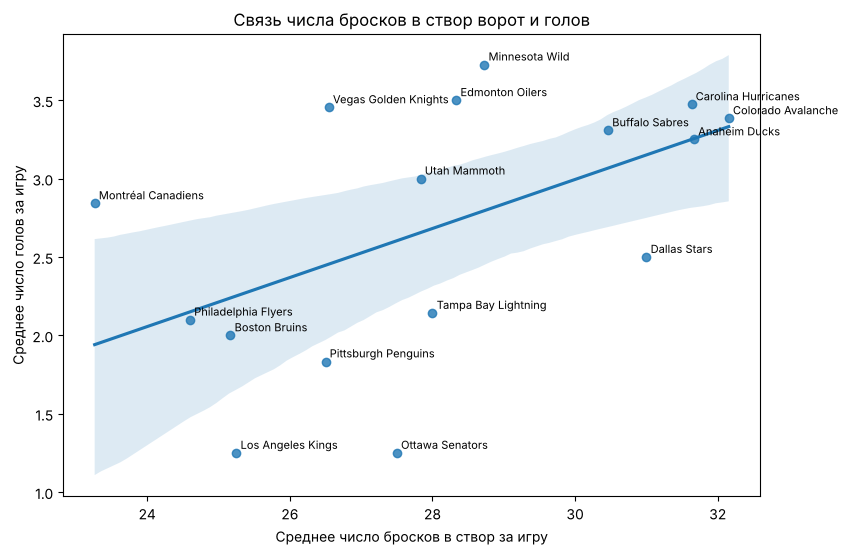

In [39]:
plt.figure(figsize=(9, 6))
sns.regplot(data=avgshots, x='Shot', y='Goal')
for team in avgshots.index:
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
                 fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')
plt.title('Связь числа бросков в створ ворот и голов')
plt.show()

In [40]:
r = avgshots['Shot'].corr(avgshots['Goal'])
print('Коэффициент корреляции: %.3f' % r)
print('Его квадрат: %.3f' % r**2)

Коэффициент корреляции: 0.521
Его квадрат: 0.271


**Выводы и комментарии.**

1. Связь видна: прямая идет вверх, то есть команды, которые больше бросают в створ, в среднем больше забивают. Это ожидаемо, ведь каждый гол это бросок в створ, и чем больше бросков, тем больше шансов забить.

2. Но связь умеренная, а не сильная. Коэффициент корреляции около 0.52. Его квадрат, примерно 0.27, показывает, что различия в числе бросков объясняют лишь около четверти различий в числе голов между командами. Остальное зависит от других факторов.

3. Это хорошо видно по точкам, которые далеко отстоят от прямой. Выше прямой находятся команды, которые забивают больше, чем можно ожидать по их броскам: Montreal Canadiens бросает меньше всех (23.3 броска за игру), но забивает 2.84 гола, а Vegas Golden Knights при средних 26.5 бросках забивает 3.45 гола. Ниже прямой Ottawa Senators (27.5 броска и только 1.25 гола), Los Angeles Kings и Dallas Stars, которая бросает много (31 бросок), но забивает всего 2.5 гола.

4. Отклонения объясняются реализацией из пункта 12: важно не только сколько команда бросает, но и откуда, насколько опасны ее броски и насколько хорошо играет вратарь соперника. Кроме того, точек всего 16, поэтому доверительная полоса широкая, и при другом составе участников наклон прямой мог бы заметно измениться. Итог: связь есть, но по одному числу бросков голы предсказываются плохо.

## Пункт 14. Матч с наибольшим числом ударов

**Условие.** Найдите матч, в котором было совершено больше всего ударов по воротам (считайте все удары, включая промахи и заблокированные `blocked-shot`).

**Решение.** Ударом по воротам здесь считается любая попытка броска: бросок в створ, гол, бросок мимо и заблокированный бросок. В пункте 10 заблокированные броски не учитывались, а здесь условие прямо требует их включить, потому что нас интересует общее число попыток, а не их точность. Для каждого матча считаем число таких событий и находим матч с наибольшим значением методом `idxmax()`, который возвращает номер этой игры. Для сравнения выводим и среднее число ударов за матч.

Чтобы отделить длительность матча от его напряженности, по последнему событию матча определяем, сколько минут он длился, и пересчитываем число ударов на 60 минут игры.

In [41]:
allShots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]
shotsPerGame = allShots.groupby('Game ID').size()
idxmax = shotsPerGame.idxmax()
print('Ударов в матче:', shotsPerGame.max())
print('В среднем за матч:', round(shotsPerGame.mean(), 1))
gameInfo(idxmax)

Ударов в матче: 208
В среднем за матч: 122.7


'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

In [42]:
lastEvent = events[events['Game ID'] == idxmax].iloc[-1]
print('Матч закончился в периоде %d на отметке %s' % (lastEvent['Period'], lastEvent['Elapsed Time']))
minutes = (lastEvent['Period'] - 1) * 20 + int(lastEvent['Elapsed Time'][:2]) + int(lastEvent['Elapsed Time'][3:]) / 60
print('Длительность матча, минут: %.1f' % minutes)
print('Ударов в пересчете на 60 минут: %.1f' % (shotsPerGame.max() / minutes * 60))

Матч закончился в периоде 5 на отметке 13:53
Длительность матча, минут: 93.9
Ударов в пересчете на 60 минут: 132.9


**Выводы и комментарии.**

1. Больше всего ударов, 208, было в матче Carolina Hurricanes - Ottawa Senators, который закончился со счетом 3:2 после двух овертаймов. Это совпадает с примером из условия. В среднем в матче плей-офф было около 123 ударов, то есть здесь их было на 70% больше обычного.

2. Главная причина в длительности матча. Он закончился на 14-й минуте второго овертайма и длился почти 94 минуты вместо обычных 60. Чем дольше идет игра, тем больше успевают бросить.

3. Но дело не только во времени. Если пересчитать 208 ударов на 60 минут игры, получится около 133 ударов, что все равно больше среднего. Значит, матч был еще и очень напряженным: обе команды много атаковали, а в овертаймах каждая старалась забить решающий гол.

## Пункт 15. Карта ударов в этом матче

**Условие.** Нарисуйте диаграмму рассеивания (`seaborn.scatterplot()`), на которой изобразите точки, с которых наносились броски в матче, найденном в предыдущем пункте. Раскрасьте точки в соответствии с исходами ударов (переменная `Play Type`). Для рисования площадки можно воспользоваться функцией `plot_rink` из файла `rink.py`. Удары гостей нарисуйте так, как будто они бьют в левые от нас ворота, а удары хозяев в правые. Для этого преобразуйте их координаты в нечетных периодах: (x, y) -> (-x, -y).

**Решение.** Координаты в данных записаны относительно площадки, а команды после каждого периода меняются воротами. Если нарисовать удары как есть, удары одной команды окажутся у разных ворот в разных периодах, и картинку будет трудно читать. Поэтому условие предлагает развернуть координаты в нечетных периодах: замена (x, y) на (-x, -y) это поворот на 180 градусов вокруг центра площадки, он меняет ворота местами.

Перед разворотом нужно проверить, что он дает нужный результат именно в этом матче. После разворота хозяева должны атаковать правые ворота, а это верно, только если в нечетных периодах они защищают правые ворота (и атакуют левые). Мы выводим поле `Home Team's Defending Side` по периодам и видим, что в периодах 1, 3 и 5 хозяева защищают правые ворота, а в периодах 2 и 4 левые. Значит, правило из условия подходит. В других матчах стороны в первом периоде бывают другими, и для них разворачивать нужно было бы четные периоды.

На рисунке цвет точки показывает исход удара, а форма маркера показывает команду: треугольник, смотрящий вправо, у хозяев, влево у гостей, по направлению их атаки. Отметим одну особенность данных: у заблокированного броска поле `Team Making the Play` указывает команду, которая бросала (а в поле первого игрока записан заблокировавший игрок соперника). Поэтому заблокированные броски корректно относятся к бросающей команде и отмечают место, где бросок был заблокирован.

In [43]:
game = allShots[allShots['Game ID'] == idxmax].copy()
game.groupby('Period')["Home Team's Defending Side"].first()

Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: str

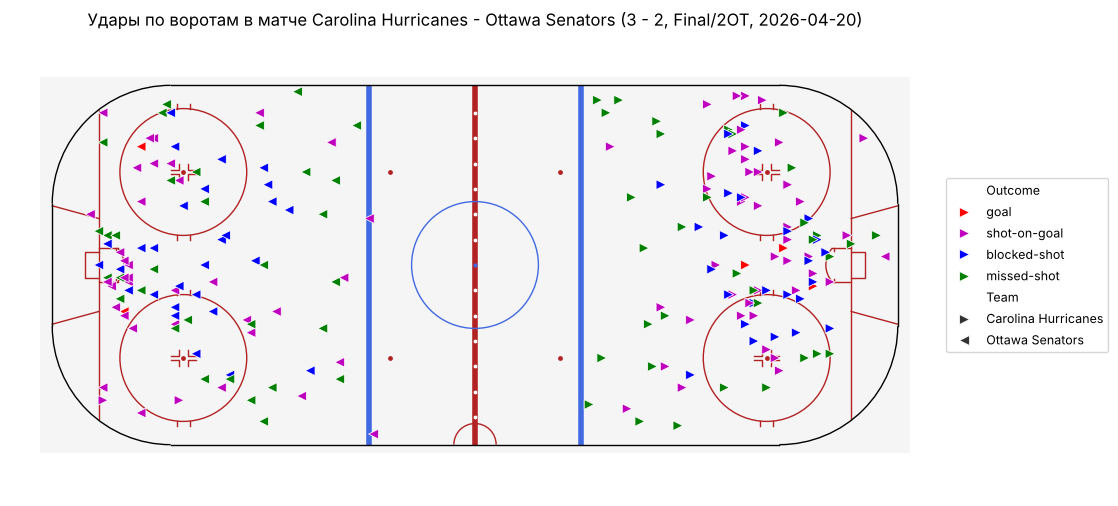

In [44]:
odd = game['Period'] % 2 == 1
game['x'] = np.where(odd, -game['X Coordinate on the Ice Rink'], game['X Coordinate on the Ice Rink'])
game['y'] = np.where(odd, -game['Y Coordinate on the Ice Rink'], game['Y Coordinate on the Ice Rink'])
game = game.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

plt.figure(figsize=(12, 6))
plot_rink()
sns.scatterplot(data=game, x='x', y='y', hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette=['red', 'm', 'b', 'g'],
                style_order=['Carolina Hurricanes', 'Ottawa Senators'], markers=['>', '<'], s=50)
plt.axis('equal')
plt.axis('off')
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=9)
plt.title('Удары по воротам в матче ' + gameInfo(idxmax))
plt.show()

In [45]:
game.groupby(['Team', 'Outcome']).size()

Team                 Outcome     
Carolina Hurricanes  blocked-shot    26
                     goal             3
                     missed-shot     34
                     shot-on-goal    46
Ottawa Senators      blocked-shot    28
                     goal             2
                     missed-shot     32
                     shot-on-goal    37
dtype: int64

**Выводы и комментарии.**

1. Хозяева, Carolina Hurricanes, нанесли 109 ударов, а гости, Ottawa Senators, 99. Перевес Carolina в основном за счет бросков в створ: 46 против 37 (без учета голов). Заблокированных бросков и промахов у команд почти поровну: 26 и 28 заблокированных, 34 и 32 промаха.

2. Почти все удары нанесены из зоны атаки, между синей линией и воротами. Из средней зоны бьют редко. Больше всего ударов сосредоточено прямо перед воротами и в кругах вбрасывания, откуда бросать опаснее всего.

3. Заблокированные броски (синие) расположены в основном дальше от ворот, ближе к синей линии. Это броски защитников издалека, на пути которых много игроков соперника. Броски с близкого расстояния реже блокируют, потому что перед воротами у защищающихся меньше времени подставиться.

4. Все 5 голов, 3 у Carolina и 2 у Ottawa, забиты из зоны атаки, недалеко от ворот. Это согласуется с пунктом 9: опасные моменты возникают вблизи ворот, а броски издалека редко заканчиваются голом.

## Пункт 16. Лучшие снайперы

**Условие.** Выведите список из десяти игроков, которые забили больше всех голов в плей-офф (поле `Player in the Event #1` для `Play Type`, равного `goal`).

**Решение.** Автор гола записан в поле `Player in the Event #1` у события типа 'goal', поэтому достаточно посчитать, сколько раз каждый игрок встречается в этом поле среди голов. Таблицу голов сохраняем отдельно, она понадобится и в пунктах 17 и 18.

При выборе десяти лучших учитываем равенство. Если на десятом месте несколько игроков с одинаковым числом голов, простое "взять первые 10" отрезало бы часть из них случайным образом, в зависимости от того, в каком порядке их расположил pandas. Поэтому выводим всех игроков, у которых голов не меньше, чем у десятого (параметр `keep='all'`), и список может оказаться длиннее 10.

Чтобы было видно, за какую команду играет каждый игрок, рядом выводим его команду. Ее определяем по событиям, в которых игрок сам совершал действие (голы, броски, силовые приемы, потери и перехваты шайбы, выигранные вбрасывания): в них поле `Team Making the Play` указывает его команду. Заблокированные броски и удаления не берем, потому что в них в поле первого игрока может стоять игрок соперника. Для каждого игрока берем команду, которая встречается у него чаще всего. Эта таблица команд пригодится и в пунктах 17-20.

In [46]:
goals = events[events['Play Type'] == 'goal']
goalsCount = goals['Player in the Event #1'].value_counts()

# Команда игрока: та, за которую он чаще всего сам совершал действия
ownActions = events[events['Play Type'].isin(['goal', 'shot-on-goal', 'missed-shot', 'hit',
                                              'giveaway', 'takeaway', 'faceoff'])]
playerTeam = ownActions.groupby('Player in the Event #1')['Team Making the Play'].agg(
    lambda s: s.value_counts().index[0])

topGoals = goalsCount.nlargest(10, keep='all')
pd.DataFrame({'Goals': topGoals, 'Team': playerTeam[topGoals.index]})

,Goals,Team
Player in the Event #1,,
Brett Howden,14,Vegas Golden Knights
Pavel Dorofeyev,12,Vegas Golden Knights
Logan Stankoven,11,Carolina Hurricanes
Mitch Marner,10,Vegas Golden Knights
Nikolaj Ehlers,8,Carolina Hurricanes
Jordan Staal,8,Carolina Hurricanes
Alex Newhook,7,Montréal Canadiens
Taylor Hall,7,Carolina Hurricanes
Jackson Blake,7,Carolina Hurricanes


**Выводы и комментарии.**

1. Лучший снайпер плей-офф Brett Howden из Vegas Golden Knights, 14 голов. За ним Pavel Dorofeyev (Vegas, 12 голов), Logan Stankoven (Carolina, 11) и Mitch Marner (Vegas, 10).

2. Вся первая четверка из команд-финалистов, Vegas и Carolina. Это закономерно: Vegas сыграла 22 матча, а Carolina 19, тогда как команды, выбывшие в первом раунде, только 4-7. Общее число голов за плей-офф сильно зависит от того, как далеко прошла команда, поэтому этот рейтинг отражает не только мастерство игрока, но и успех его команды.

3. Места с 7-го по 12-е делят шесть игроков с 7 голами, поэтому в списке 12 человек. Отрезать двоих из них было бы несправедливо, ведь у них столько же голов, сколько у остальных.

## Пункт 17. Лучшие ассистенты

**Условие.** Выведите список из десяти игроков, которые набрали больше всех голевых передач в плей-офф (поля `Player in the Event #2` и `Player in the Event #3` для `Play Type`, равного `goal`).

**Решение.** У каждого гола может быть до двух голевых передач: в поле `Player in the Event #2` записан игрок, отдавший последний пас, а в поле `Player in the Event #3` игрок, отдавший пас перед ним. По правилам обе передачи засчитываются одинаково. Поэтому мы объединяем оба поля в один общий список и считаем, сколько раз в нем встречается каждый игрок. Так каждая передача учитывается ровно один раз, в каком бы поле она ни стояла. Если у гола была только одна передача или их не было вовсе, соответствующее поле пустое, и при подсчете такие пустые значения не учитываются.

In [47]:
assistsCount = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).value_counts()
topAssists = assistsCount.nlargest(10, keep='all')
pd.DataFrame({'Assists': topAssists, 'Team': playerTeam[topAssists.index]})

,Assists,Team
Jack Eichel,20,Vegas Golden Knights
Mitch Marner,19,Vegas Golden Knights
Lane Hutson,13,Montréal Canadiens
Jackson Blake,13,Carolina Hurricanes
Nick Suzuki,12,Montréal Canadiens
Taylor Hall,12,Carolina Hurricanes
Martin Necas,12,Colorado Avalanche
Shea Theodore,12,Vegas Golden Knights
Kirill Kaprizov,11,Minnesota Wild
Quinn Hughes,11,Minnesota Wild


**Выводы и комментарии.**

1. Больше всего голевых передач у Jack Eichel (20) и Mitch Marner (19), оба из Vegas Golden Knights. С большим отрывом за ними идут Lane Hutson и Jackson Blake (по 13).

2. Как и в пункте 16, в списке преобладают игроки команд, сыгравших больше всего матчей: Vegas (Eichel, Marner, Theodore), Carolina (Blake, Hall) и Montreal, дошедшая до финала конференции (Hutson, Suzuki). Также в списке Martin Necas из Colorado Avalanche, дошедшей до финала конференции, и Kirill Kaprizov и Quinn Hughes из Minnesota Wild, дошедшей до второго раунда.

3. В списке заметно много защитников, например Lane Hutson, Shea Theodore и Quinn Hughes. Защитники редко забивают сами, но часто участвуют в розыгрыше шайбы от синей линии и поэтому набирают много вторых передач.

4. Здесь на 10-м месте ровно два игрока с 11 передачами, следующий игрок отстает, поэтому список состоит ровно из 10 человек.

## Пункт 18. Лучшие бомбардиры (гол + пас)

**Условие.** Выведите список из десяти игроков, которые набрали больше всего очков по системе гол плюс пас.

**Решение.** По системе гол плюс пас игрок получает одно очко за каждый свой гол и одно очко за каждую голевую передачу. Значит, число очков равно числу появлений игрока во всех трех полях у голов: в первом как автора гола и во втором и третьем как ассистента. Поэтому объединяем все три поля в один список и считаем появления каждого игрока, это и есть его очки.

Чтобы было видно, из чего сложились очки, рядом выводим отдельно голы (из пункта 16) и передачи (из пункта 17). Это заодно служит проверкой: в каждой строке сумма голов и передач должна равняться числу очков. Как и раньше, учитываем всех, кто делит десятое место.

In [48]:
pointsCount = pd.concat([goals['Player in the Event #1'],
                         goals['Player in the Event #2'],
                         goals['Player in the Event #3']]).value_counts()
topPoints = pointsCount.nlargest(10, keep='all')
pd.DataFrame({'Goals': goalsCount.reindex(topPoints.index, fill_value=0),
              'Assists': assistsCount.reindex(topPoints.index, fill_value=0),
              'Points': topPoints,
              'Team': playerTeam[topPoints.index]})

,Goals,Assists,Points,Team
Mitch Marner,10,19,29,Vegas Golden Knights
Jack Eichel,2,20,22,Vegas Golden Knights
Jackson Blake,7,13,20,Carolina Hurricanes
Taylor Hall,7,12,19,Carolina Hurricanes
Brett Howden,14,4,18,Vegas Golden Knights
Shea Theodore,6,12,18,Vegas Golden Knights
Nikolaj Ehlers,8,10,18,Carolina Hurricanes
Lane Hutson,3,13,16,Montréal Canadiens
Nick Suzuki,4,12,16,Montréal Canadiens
Logan Stankoven,11,5,16,Carolina Hurricanes


**Выводы и комментарии.**

1. Лучший бомбардир плей-офф Mitch Marner из Vegas Golden Knights, 29 очков (10 голов и 19 передач). Он со значительным отрывом опережает второго, Jack Eichel (22 очка).

2. Разложение очков на голы и передачи показывает разные роли игроков. Jack Eichel набрал 22 очка почти только за счет передач (2 гола и 20 передач), это типичный распасовщик. Brett Howden, наоборот, набрал 18 очков в основном голами (14 голов и 4 передачи), это снайпер. Pavel Dorofeyev и Logan Stankoven тоже набрали очки в основном голами, а Lane Hutson и Nick Suzuki в основном передачами.

3. Как и в пунктах 16 и 17, лидируют игроки Vegas и Carolina, которые сыграли больше всего матчей.

4. На 10-м месте четыре игрока с 16 очками, поэтому в списке 11 человек.

## Пункт 19. Больше всего бросков в створ за игру

**Условие.** Выведите список из десяти игроков, которые в среднем нанесли больше всего бросков в створ ворот за одну игру.

**Решение.** Броском в створ, как и в пункте 12, считаем события 'shot-on-goal' и 'goal', а бросающий игрок записан в поле `Player in the Event #1`. Среднее за игру это число бросков игрока, деленное на число игр, и главный вопрос в том, какие игры считать.

Мы делим на число матчей, в которых игрок был на льду. Матч засчитывается игроку, если его фамилия хотя бы раз встречается в столбцах игроков на льду или вратарей. Можно было бы делить только на матчи, где игрок сделал хотя бы один бросок, но тогда матчи без бросков выпали бы из расчета (так же, как матчи без голов в пункте 12), и среднее оказалось бы завышенным. Например, у David Pastrnak 22 броска в 6 матчах, то есть 3.67 за игру, а если не считать матч без бросков, получилось бы 4.4.

Чтобы посчитать число матчей каждого игрока, мы составляем таблицу пар (игра, игрок) из всех столбцов составов и убираем в ней повторы, ведь один игрок встречается в сотнях событий одного матча. После этого число строк с данной фамилией и есть число сыгранных матчей. Минимального порога по числу матчей мы не ставим, а игроков, которые делят десятое место, выводим всех.

In [49]:
pairs = []
for col in cols:
    pairs.append(events[['Game ID', col]].rename(columns={col: 'Player'}))
onIce = pd.concat(pairs).dropna().drop_duplicates()
gamesByPlayer = onIce['Player'].value_counts()
gamesByPlayer.head()

Player
Rasmus Andersson    22
Ivan Barbashev      22
Pavel Dorofeyev     22
Carter Hart         22
Nic Dowd            22
Name: count, dtype: int64

In [50]:
sogCount = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]['Player in the Event #1'].value_counts()
sogTable = pd.DataFrame({'Shots on Goal': sogCount,
                         'Games': gamesByPlayer[sogCount.index],
                         'Team': playerTeam[sogCount.index]})
sogTable['Per Game'] = sogTable['Shots on Goal'] / sogTable['Games']
sogTable.nlargest(10, 'Per Game', keep='all')

,Shots on Goal,Games,Team,Per Game
Player in the Event #1,,,,
Jason Robertson,30,6,Dallas Stars,5.000
Dylan Guenther,27,6,Utah Mammoth,4.500
Nikita Kucherov,31,7,Tampa Bay Lightning,4.429
Matt Boldy,48,11,Minnesota Wild,4.364
Quinton Byfield,17,4,Los Angeles Kings,4.250
Darren Raddysh,28,7,Tampa Bay Lightning,4.000
Joel Eriksson Ek,24,6,Minnesota Wild,4.000
Alex Laferriere,15,4,Los Angeles Kings,3.750
David Pastrnak,22,6,Boston Bruins,3.667


**Выводы и комментарии.**

1. Больше всего бросков в створ за игру делал Jason Robertson из Dallas Stars, 5 бросков в среднем за 6 матчей. За ним идут Dylan Guenther (Utah Mammoth, 4.5) и Nikita Kucherov (Tampa Bay Lightning, 4.43).

2. Этот рейтинг сильно отличается от рейтингов в пунктах 16-18. Там лидировали игроки финалистов, потому что они сыграли больше всего матчей. Здесь среднее за игру уравнивает игроков из команд, которые прошли далеко и вылетели рано, и в первую тройку попали игроки команд, выбывших уже в первом раунде.

3. Самые надежные результаты у игроков, которые много бросали на протяжении многих матчей: Matt Boldy (Minnesota Wild) сделал 48 бросков в створ за 11 матчей, а Nathan MacKinnon (Colorado Avalanche) 47 бросков за 13 матчей. У игроков с 4-6 матчами среднее сильнее зависит от случайности.

4. Интересно, что четверка лучших снайперов из пункта 16 (Howden, Dorofeyev, Stankoven, Marner) в этот список не попала, а из всего списка снайперов здесь есть только Matt Boldy и Nathan MacKinnon. Значит, больше всех забивают не обязательно те, кто больше всех бросает, а те, кто бросает из выгодных позиций и хорошо реализует моменты. Это согласуется с выводом пункта 13.

## Пункт 20. Больше всего силовых приемов за игру

**Условие.** Выведите список из десяти игроков, которые в среднем провели больше всего силовых приемов за одну игру (поле `Player in the Event #1` для `Play Type`, равного `hit`).

**Решение.** Пункт решается так же, как пункт 19, только вместо бросков считаются силовые приемы, события типа 'hit', где в поле `Player in the Event #1` записан игрок, проводивший прием. Число приемов делим на число матчей, в которых игрок был на льду, по тем же причинам, что и в пункте 19. Число матчей каждого игрока уже посчитано в пункте 19, поэтому заново его не считаем.

In [51]:
hitCount = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()
hitTable = pd.DataFrame({'Hits': hitCount,
                         'Games': gamesByPlayer[hitCount.index],
                         'Team': playerTeam[hitCount.index]})
hitTable['Per Game'] = hitTable['Hits'] / hitTable['Games']
hitTable.nlargest(10, 'Per Game', keep='all')

,Hits,Games,Team,Per Game
Player in the Event #1,,,,
Lawson Crouse,38,6,Utah Mammoth,6.333
Alex Turcotte,6,1,Los Angeles Kings,6.000
Alexander Petrovic,6,1,Dallas Stars,6.000
Yakov Trenin,51,9,Minnesota Wild,5.667
Dylan Cozens,22,4,Ottawa Senators,5.500
Vasily Podkolzin,32,6,Edmonton Oilers,5.333
Ivan Barbashev,110,22,Vegas Golden Knights,5.000
Marcus Foligno,55,11,Minnesota Wild,5.000
Carl Grundstrom,15,3,Philadelphia Flyers,5.000


**Выводы и комментарии.**

1. Больше всего силовых приемов за игру проводил Lawson Crouse из Utah Mammoth, в среднем 6.33 приема за 6 матчей. Далее идут Yakov Trenin (Minnesota Wild, 5.67) и Dylan Cozens (Ottawa Senators, 5.5).

2. На втором и третьем местах оказались Alex Turcotte и Alexander Petrovic, но они сыграли всего по одному матчу и провели в нем по 6 силовых приемов. По одному матчу нельзя судить о манере игры, это может быть случайный результат. Мы не ставили порог по числу матчей, поэтому они попали в список, но относиться к их местам нужно осторожно.

3. Самый показательный результат у Ivan Barbashev из Vegas Golden Knights: 110 силовых приемов за 22 матча, ровно 5 за игру. Удерживать такую интенсивность на протяжении всего плей-офф гораздо труднее, чем в нескольких матчах.

4. В отличие от рейтингов по голам и очкам, здесь нет звезд нападения. Силовые приемы проводят в основном игроки силового, оборонительного склада, чья задача навязывать борьбу и изматывать соперника.

## Пункт 21. Вратари, не пропустившие ни одного гола

**Условие.** Выведите список всех вратарей, которые хотя бы в одном матче не пропустили ни одного гола (даже в тех случаях, когда играли не полную игру, а выходили на замену или наоборот были заменены).

**Решение.** Главное здесь правильно определить, на какого вратаря записывать каждый гол. Мы записываем гол на вратаря, который стоял в воротах пропустившей команды в момент гола: если забили хозяева, это вратарь гостей, если гости, то вратарь хозяев. Такой подход правильно учитывает замены, о которых говорится в условии. Вратарь, вышедший на замену, отвечает только за голы, забитые, пока он был на льду, а вратарь, которого заменили, только за голы до замены. Если в момент гола вратаря на льду не было, потому что команда сняла его ради лишнего полевого игрока, гол забит в пустые ворота и ни на кого не записывается.

При проверке данных обнаружилась проблема. У 111 событий, в том числе у 22 голов, составы не заполнены совсем: у обеих команд записано 0 игроков на льду, и все поля игроков и вратарей пустые. Это не пустые ворота (тогда пустым было бы только поле одного вратаря, а остальные игроки были бы записаны), а пропуск в данных. Если оставить эти события как есть, такие голы не запишутся ни на одного вратаря. В частности, в двух матчах со счетом 1:0 единственный гол в овертайме записан именно без составов, и проигравшие вратари Arturs Silovs и Jakub Dobes ошибочно попали бы в список.

Поэтому для событий без составов мы берем вратарей из предыдущего события того же матча: в ворота за доли секунды до гола вратарь смениться не мог. Заполнение делаем только внутри одного матча и только для событий, где составы пусты полностью, чтобы не испортить настоящие голы в пустые ворота.

После этого для каждого вратаря в каждом матче считаем пропущенные голы. В список вратарей матча включаем всех, кто был в воротах хотя бы в одном событии, поэтому учитываются и вратари, которые отыграли только часть встречи. Вратарь, который не пропустил ни одного гола, в таблице пропущенных голов отсутствует, и для него число пропущенных равно 0. Остается выбрать матчи с нулем пропущенных голов.

Для комментария дополнительно смотрим, в каких периодах каждый из этих вратарей стоял в воротах, чтобы отличить полные матчи от выходов на замену. И для сравнения показываем, какой список получился бы без заполнения пропусков в составах.

In [52]:
goalieCols = ["Away Team's Goalie", "Home Team's Goalie"]
noLineup = ((events["# of Away Team's Players on the Ice"] == 0) &
            (events["# of Home Team's Players on the Ice"] == 0))
print('Событий без составов:', noLineup.sum())
print('Из них голов:', (noLineup & (events['Play Type'] == 'goal')).sum())

filled = events.groupby('Game ID')[goalieCols].ffill()
ev = events.copy()
for col in goalieCols:
    ev[col] = np.where(noLineup, filled[col], events[col])

Событий без составов: 111
Из них голов: 22


In [53]:
goalEv = ev[ev['Play Type'] == 'goal'].copy()
goalEv['Conceded By'] = np.where(goalEv['Team Making the Play'] == goalEv['Home Team'],
                                 goalEv["Away Team's Goalie"], goalEv["Home Team's Goalie"])
print('Голов в пустые ворота:', pd.isna(goalEv['Conceded By']).sum())
conceded = goalEv.groupby(['Game ID', 'Conceded By']).size()
conceded.head()

Голов в пустые ворота: 3


Game ID     Conceded By         
2025030111  Jeremy Swayman          4
            Ukko-Pekka Luukkonen    3
2025030112  Alex Lyon               1
            Jeremy Swayman          2
            Ukko-Pekka Luukkonen    3
dtype: int64

In [54]:
pairs = []
for col in goalieCols:
    pairs.append(ev[['Game ID', col]].rename(columns={col: 'Goalie'}))
played = pd.concat(pairs).dropna().drop_duplicates()
played['Goals Against'] = [conceded.get((gameId, goalie), 0)
                           for gameId, goalie in zip(played['Game ID'], played['Goalie'])]

shutouts = played[played['Goals Against'] == 0].sort_values(['Goalie', 'Game ID'])
shutouts['Game Info'] = [gameInfo(gameId) for gameId in shutouts['Game ID']]
shutouts[['Goalie', 'Game ID', 'Game Info']]

,Goalie,Game ID,Game Info
3960,Andrei Vasilevskiy,2025030126,Montréal Canadiens - Tampa Bay Lightning (0 - ...
29367,Brandon Bussi,2025030416,Vegas Golden Knights - Carolina Hurricanes (0 ...
6653,Dan Vladar,2025030142,Pittsburgh Penguins - Philadelphia Flyers (0 -...
8110,Dan Vladar,2025030146,Philadelphia Flyers - Pittsburgh Penguins (1 -...
4679,Frederik Andersen,2025030131,"Carolina Hurricanes - Ottawa Senators (2 - 0, ..."
19100,Frederik Andersen,2025030221,Carolina Hurricanes - Philadelphia Flyers (3 -...
25460,Frederik Andersen,2025030314,Montréal Canadiens - Carolina Hurricanes (0 - ...
1379,Joonas Korpisalo,2025030114,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ..."
22130,Scott Wedgewood,2025030235,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi..."


In [55]:
sorted(set(shutouts['Goalie']))

['Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood']

In [56]:
# В каких периодах вратарь стоял в воротах
def periodsInNet(gameId, goalie):
    g = ev[ev['Game ID'] == gameId]
    inNet = g[(g["Away Team's Goalie"] == goalie) | (g["Home Team's Goalie"] == goalie)]
    return ', '.join([str(p) for p in sorted(set(inNet['Period']))])

shutouts['Periods in Net'] = [periodsInNet(gameId, goalie)
                              for gameId, goalie in zip(shutouts['Game ID'], shutouts['Goalie'])]
shutouts[['Goalie', 'Game Info', 'Periods in Net']]

,Goalie,Game Info,Periods in Net
3960,Andrei Vasilevskiy,Montréal Canadiens - Tampa Bay Lightning (0 - ...,"1, 2, 3, 4"
29367,Brandon Bussi,Vegas Golden Knights - Carolina Hurricanes (0 ...,"1, 2, 3"
6653,Dan Vladar,Pittsburgh Penguins - Philadelphia Flyers (0 -...,"1, 2, 3"
8110,Dan Vladar,Philadelphia Flyers - Pittsburgh Penguins (1 -...,"1, 2, 3, 4"
4679,Frederik Andersen,"Carolina Hurricanes - Ottawa Senators (2 - 0, ...","1, 2, 3"
19100,Frederik Andersen,Carolina Hurricanes - Philadelphia Flyers (3 -...,"1, 2, 3"
25460,Frederik Andersen,Montréal Canadiens - Carolina Hurricanes (0 - ...,"1, 2, 3"
1379,Joonas Korpisalo,"Boston Bruins - Buffalo Sabres (1 - 6, Final, ...",3
22130,Scott Wedgewood,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi...","2, 3, 4"


In [57]:
# Для сравнения: список без заполнения пропусков в составах
raw = events[events['Play Type'] == 'goal'].copy()
raw['Conceded By'] = np.where(raw['Team Making the Play'] == raw['Home Team'],
                              raw["Away Team's Goalie"], raw["Home Team's Goalie"])
concededRaw = raw.groupby(['Game ID', 'Conceded By']).size()
sorted(set([goalie for gameId, goalie in zip(played['Game ID'], played['Goalie'])
            if concededRaw.get((gameId, goalie), 0) == 0]))

['Andrei Vasilevskiy', 'Arturs Silovs', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Jakub Dobes', 'Joonas Korpisalo', 'Scott Wedgewood']

**Выводы и комментарии.**

1. Хотя бы в одном матче не пропустили ни одного гола 6 вратарей: Andrei Vasilevskiy, Brandon Bussi, Dan Vladar, Frederik Andersen, Joonas Korpisalo и Scott Wedgewood. Всего таких случаев 9.

2. Лучше всех Frederik Andersen из Carolina Hurricanes: у него 3 сухих матча, по одному в каждом из первых трех раундов. Еще один сухой матч у его партнера по команде Brandon Bussi, причем это был последний матч финала, Vegas Golden Knights - Carolina Hurricanes 0:3, в котором Carolina выиграла Кубок. Таким образом, на счету вратарей чемпиона 4 сухих матча из 9, и надежная игра в воротах во многом объясняет, почему Carolina выиграла, несмотря на невысокую точность бросков (пункт 11).

3. У Dan Vladar из Philadelphia Flyers 2 сухих матча, оба против Pittsburgh Penguins в первом раунде, причем один из них это матч 1:0 в овертайме из пункта 6. Andrei Vasilevskiy (Tampa Bay Lightning) отыграл на ноль второй матч 1:0, тоже в овертайме.

4. Двое вратарей попали в список благодаря замене, как и предусмотрено условием. Joonas Korpisalo (Boston Bruins) вышел на третий период в матче, который его команда проиграла 1:6, и больше голов не пропустил. Scott Wedgewood (Colorado Avalanche) заменил основного вратаря по ходу второго периода, отыграл до конца без пропущенных голов, и его команда выиграла 4:3 в овертайме. Остальные отыграли свои сухие матчи полностью.

5. Без исправления пропусков в составах в списке оказались бы еще Arturs Silovs и Jakub Dobes. Но оба проиграли свои матчи 0:1 и, значит, пропустили единственный гол, так что исправление было необходимо.

## Пункт 22. Собственный вопрос: есть ли преимущество своей площадки?

**Условие.** Придумайте какой-нибудь содержательный вопрос, связанный с рассматриваемым набором данных, и ответьте на него.

**Решение.** Мы проверяем, есть ли у хозяев преимущество своей площадки. Принято считать, что дома играть легче: поддерживает своя публика, команде не нужно ездить, а по правилам хозяева имеют небольшие тактические преимущества (например, последними делают замену перед вбрасыванием). Мы проверяем, подтверждается ли это в плей-офф 2026 года.

Сначала считаем самый прямой показатель, долю побед хозяев. Ничьих в плей-офф не бывает, поэтому если бы площадка ничего не давала, хозяева выигрывали бы примерно половину матчей. Но доля, посчитанная по 82 матчам, сама содержит случайную погрешность, и даже при равных шансах она почти никогда не получилась бы ровно 0.5. Чтобы понять, можно ли объяснить отличие случайностью, считаем стандартную ошибку доли по формуле sqrt(p * (1 - p) / n) и строим примерный 95-процентный интервал: доля плюс-минус две стандартные ошибки. Если 0.5 попадает в интервал, данные не позволяют утверждать, что хозяева выигрывают чаще или реже половины матчей.

Затем сравниваем средние показатели хозяев и гостей за матч: голы, броски в створ и силовые приемы. Если площадка помогает, это должно проявляться не только в победах, но и в игре.

Самое важное рассуждение касается того, кто именно оказывается хозяином. В плей-офф серия идет до четырех побед, и команда, которая лучше выступила в регулярном сезоне, играет дома первый, второй, пятый и седьмой матчи, а более слабая только третий, четвертый и шестой. Значит, хозяевами чаще бывают более сильные команды, и простая доля побед хозяев смешивает два эффекта: силу команды и влияние площадки. Чтобы их разделить, мы определяем номер матча в серии по последней цифре номера игры и считаем долю побед хозяев отдельно в матчах, где дома играет сильнейшая команда, и в матчах, где дома играет слабейшая. Если бы главную роль играла площадка, хозяева чаще выигрывали бы в обеих группах. Если главную роль играет сила команды, доля побед хозяев будет высокой в первой группе и низкой во второй. Результат показываем на столбчатой диаграмме с линией на уровне 50%.

In [58]:
games['Home Win'] = games['Home Score'] > games['Away Score']
print('Побед хозяев: %d из %d, доля %.3f'
      % (games['Home Win'].sum(), len(games), games['Home Win'].mean()))

Побед хозяев: 39 из 82, доля 0.476


In [59]:
p = games['Home Win'].mean()
se = np.sqrt(p * (1 - p) / len(games))
print('Стандартная ошибка: %.3f' % se)
print('Примерный 95%%-й интервал: от %.2f до %.2f' % (p - 2 * se, p + 2 * se))

Стандартная ошибка: 0.055
Примерный 95%-й интервал: от 0.37 до 0.59


In [60]:
homeEvents = events['Team Making the Play'] == events['Home Team']
awayEvents = events['Team Making the Play'] == events['Away Team']

def perGame(types, mask):
    return (events['Play Type'].isin(types) & mask).sum() / len(games)

comparison = pd.DataFrame({
    'Home': [games['Home Score'].mean(), perGame(['shot-on-goal', 'goal'], homeEvents), perGame(['hit'], homeEvents)],
    'Away': [games['Away Score'].mean(), perGame(['shot-on-goal', 'goal'], awayEvents), perGame(['hit'], awayEvents)]},
    index=['Голов за матч', 'Бросков в створ за матч', 'Силовых приемов за матч'])
comparison

,Home,Away
Голов за матч,2.805,3.122
Бросков в створ за матч,28.341,28.037
Силовых приемов за матч,36.500,32.049


In [61]:
games['Game in Series'] = games.index % 10
games.groupby('Game in Series')['Home Win'].agg(['mean', 'count'])

,mean,count
Game in Series,,
1,0.600,15
2,0.533,15
3,0.533,15
4,0.267,15
5,0.636,11
6,0.333,9
7,0.000,2


In [62]:
games['Stronger Team at Home'] = games['Game in Series'].isin([1, 2, 5, 7])
games.groupby('Stronger Team at Home')['Home Win'].agg(['mean', 'count'])

,mean,count
Stronger Team at Home,,
False,0.385,39
True,0.558,43


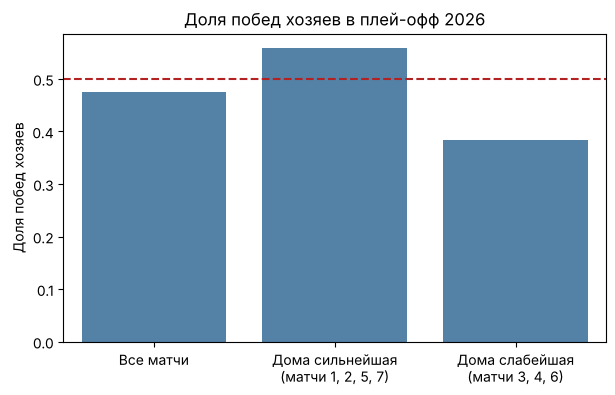

In [63]:
plt.figure(figsize=(7, 4))
sns.barplot(x=['Все матчи', 'Дома сильнейшая\n(матчи 1, 2, 5, 7)', 'Дома слабейшая\n(матчи 3, 4, 6)'],
            y=[games['Home Win'].mean(),
               games[games['Stronger Team at Home']]['Home Win'].mean(),
               games[~games['Stronger Team at Home']]['Home Win'].mean()],
            color='steelblue')
plt.axhline(0.5, color='firebrick', linestyle='--')
plt.ylabel('Доля побед хозяев')
plt.title('Доля побед хозяев в плей-офф 2026')
plt.show()

**Выводы и комментарии.**

1. Преимущества своей площадки в плей-офф 2026 не видно. Хозяева выиграли 39 матчей из 82, то есть 47.6%, даже меньше половины. Гости в среднем забивали больше хозяев (3.12 гола против 2.80), а число бросков в створ у хозяев и гостей почти одинаковое (28.3 и 28.0 за матч).

2. При этом нельзя сказать, что дома играть хуже. При 82 матчах погрешность доли большая: стандартная ошибка около 0.055, а примерный 95-процентный интервал от 0.37 до 0.59 включает 0.5. Значит, отличие доли побед хозяев от половины вполне может быть случайным, и правильный вывод звучит так: заметного преимущества своей площадки данные не показывают.

3. Сила команды оказалась важнее площадки. Когда дома играет сильнейшая по итогам регулярного сезона команда (матчи 1, 2, 5 и 7), хозяева выигрывают в 56% случаев. Когда дома играет слабейшая (матчи 3, 4 и 6), хозяева выигрывают только в 38% случаев, то есть чаще побеждают гости, более сильная команда. Если бы площадка давала большое преимущество, слабые команды дома выигрывали бы хотя бы половину матчей.

4. Отдельно стоит отметить четвертые матчи серий: хозяева выиграли лишь 4 из 15 (27%). Обычно к четвертому матчу сильная команда уже ведет в серии и дожимает соперника на его площадке. Однако в отдельных номерах матчей всего от 2 до 15 игр, поэтому такие частные цифры ненадежны.

5. Единственный показатель, где хозяева заметно впереди, это силовые приемы: 36.5 за матч против 32.0 у гостей. Но это может быть связано не с игрой, а с тем, как ведется статистика. Силовые приемы фиксируют информаторы на арене хозяев, и на разных аренах их засчитывают по-разному. Если местные информаторы чуть охотнее записывают силовые приемы своей команды, у хозяев получится больше приемов, даже если на льду разницы не было. Голы и броски в створ определяются гораздо однозначнее, и по ним разницы нет.

6. Итоговый ответ на вопрос: в плей-офф 2026 года своя площадка не давала командам ощутимого преимущества, исход матча гораздо сильнее зависел от силы команд.